# MNISTで画像分類の流れをつかむ
## ResNet-10Tを自分で定義し、読み込みから推論まで

このNotebookは、研究室で本格的な画像認識に取り組む前に、一連の処理を実際に動かして確認するための導入教材です。機械学習の理論を学んだことがあり、Pythonは初めての人を想定しています。課題や提出物はありません。

**画像と正解を用意する → 数値に変換する → モデルの構造を定義する → 学習する → 評価する → 保存して使う**

コードは上から順に、そのまま実行できます。各節では処理のまとまりを説明し、重要な文法や関数を初めて使う場所で補足します。「今後につながる知識」と参考リンクは、翌週以降に調べ直すための入口です。初回にすべて覚える必要はありません。

- データ：手書きの数字0〜9を集めたMNIST
- モデル：PyTorchの層で明示したResNet-10T（白黒入力・10クラス出力）
- 標準設定：学習1,000枚、検証200枚、テスト200枚、10エポック
- 待ち時間：GPUで数分以内の学習を目標にした設定です。初回ダウンロードと説明を読む時間は別です。実際の時間はPCによって変わり、学習セルに表示されます。
- 実行すると、このフォルダ内の `data/` にデータ、`outputs/` に学習済みモデルと記録が作られます。

### 目次

0. Notebookの使い方
1. ライブラリと計算環境
2. MNISTの読み込みと画像の確認
3. 前処理・データ分割・ミニバッチ
4. ResNetの構造を定義する
5. 損失関数と重みの更新
6. 学習と検証
7. 学習曲線
8. テストと誤分類の確認
9. 学習済みモデルの保存と再利用
10. 次に調べるための案内


## 0. Notebookの使い方

Notebookには、今読んでいるような**説明セル（Markdown）**と、Pythonを動かす**コードセル**があります。

1. コードセルを選び、**Shift + Enter**で実行して次へ進みます。
2. コード左側の `[*]` や実行中の表示が消えるまで待ちます。
3. セルの下に表示された結果を見て、次の説明を読みます。

コードを実行するPython本体を**カーネル**と呼びます。作成した変数やモデルは、同じカーネルの後続セルから使えます。そのため、途中のセルだけ実行すると、必要な変数がまだ存在せずエラーになる場合があります。

迷ったら「カーネルの再起動」を選び、先頭から実行し直してください。再起動するとメモリ上の変数は消えますが、保存したファイルは残ります。「すべて実行」も使えます。

**環境の準備は同じフォルダのREADME.mdを参照してください。** 必要なライブラリはNotebook内で自動インストールしません。準備済みのPython環境をカーネルとして選択してから始めます。


In [2]:
message = "これから手書き数字の分類を始めます"
print(message)


これから手書き数字の分類を始めます


**この塊の意味：文字を変数に入れ、画面に表示します。**

- `message` は値に付けた名前、つまり変数です。`=` は右側の値を左側の名前に代入します。
- `"…"` で囲んだ値は文字列です。`print(...)` は、括弧の中の値を表示する関数です。
- 関数に渡す値を**引数**、関数が処理して返す値を**戻り値**と呼びます。

この表示が出れば、コードセルを実行できています。Pythonでは `#` から行末まではコメントで、説明用の文字として扱われます。

参考：[Python公式チュートリアル（日本語）](https://docs.python.org/ja/3/tutorial/) — 文法や用語を調べ直すときに使います。


## 1. ライブラリと計算環境

**ライブラリ**は、他の人が用意した機能を再利用するためのプログラム集です。ここではPyTorchで学習処理を行い、TorchVisionで画像データを読み込み、Matplotlibで画像やグラフを表示します。

次のセルは使う機能を読み込むだけなので、何も表示されなくても正常です。


In [3]:
from pathlib import Path
from copy import deepcopy
import json
import time

import torch
from torch import nn
from torch.utils.data import DataLoader, random_split, Subset
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt


**この塊の意味：後で使う道具を準備します。**

- `import torch` はライブラリを読み込みます。`torch.xxx` のように `.` で中の機能にアクセスします。
- `from torch import nn` は、その中の `nn` を取り出し、短い名前で使えるようにします。`nn` はニューラルネットワークの層や損失関数をまとめたものです。
- `as plt` は別名を付ける書き方です。後で `plt.imshow(...)` のようにグラフの機能を呼び出します。
- `Path` はファイルの場所、`deepcopy` は独立したコピー、`json` は記録の保存、`time` は時間の計測に使います。これらはPython標準の機能です。
- `datasets`、`transforms`、`DataLoader` は、それぞれデータセット・前処理・データをまとめて取り出す仕組みです。具体的な使い方は後で確認します。

`ModuleNotFoundError` が出たら、そのライブラリが現在のカーネルに入っていません。READMEの環境準備と、Notebookで選択しているカーネルを確認してください。


In [4]:
SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name != "B3CNNpart" and (PROJECT_DIR / "B3CNNpart").is_dir():
    PROJECT_DIR = PROJECT_DIR / "B3CNNpart"

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("計算に使う場所:", device)
print("保存先:", PROJECT_DIR)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPUで実行します。GPUを使う予定ならREADMEの確認事項を参照してください。")


PyTorch: 2.5.1+cu118
TorchVision: 0.20.1+cu118
計算に使う場所: cuda
保存先: /home/B3CNNpart
GPU: NVIDIA GeForce RTX 4090


**この塊の意味：乱数、計算先、保存先を決めます。**

`torch.manual_seed(SEED)` は乱数の出発点を固定します。重みの初期値やデータの順序に乱数を使うため、条件をそろえる助けになります。ただし、GPU・ライブラリのバージョンなどが違うと完全に同じ結果になるとは限りません。

`device` は計算する場所です。`"cuda" if 条件 else "cpu"` は「条件を満たせばcuda、そうでなければcpu」を選ぶ書き方です。CUDAはNVIDIAのGPUを計算に使うための基盤です。GPUを搭載していても、対応するPyTorchやドライバが使えなければ `False` になります。

`if ...:` の次の行から字下げされた部分は、条件を満たしたときだけ実行します。Pythonでは、この**インデント**で処理のまとまりを表します。後で使う繰り返しや関数でも同じです。

`Path.cwd()` は現在の作業フォルダです。`Path` に対する `/` はフォルダ名をつなぎます。`mkdir(...)` はフォルダを作り、`exist_ok=True` は既に存在していてもエラーにしない指定です。通常はこのNotebookのあるB3CNNpartを作業フォルダとして使ってください。

**今後につながる知識：** 同じ研究結果を再現するには、乱数だけでなくデータ分割・前処理・ライブラリのバージョンも記録します。

検索語：`PyTorch reproducibility`、`CUDA torch.cuda.is_available`  
参考：[再現性に関する公式説明](https://docs.pytorch.org/docs/stable/notes/randomness.html)、[PyTorchのインストール選択画面](https://pytorch.org/get-started/locally/)


## 2. MNISTの読み込みと画像の確認

MNISTには、0〜9の数字を表す**28×28画素のグレースケール画像**と正解ラベルが入っています。公式の学習用60,000枚とテスト用10,000枚が用意されています。

1画素は画像を構成する小さな点です。グレースケールでは1つの値で明るさを表します。RGBカラー画像なら、赤・緑・青の3つの値を持ちます。この成分の数を**チャネル数**と呼びます。

まず、加工前の画像を読み込みます。初回はインターネットからダウンロードするため、少し待ちます。2回目以降は保存済みデータを利用します。


学習用データ全体の枚数: 60000
1枚の画像のサイズ: (28, 28)
正解ラベル: 5


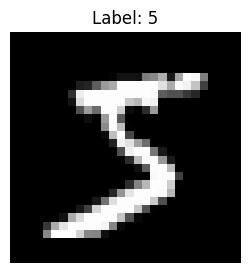

In [5]:
raw_train = datasets.MNIST(root=DATA_DIR, train=True, download=True)

raw_image, raw_label = raw_train[0]
print("学習用データ全体の枚数:", len(raw_train))
print("1枚の画像のサイズ:", raw_image.size)
print("正解ラベル:", raw_label)

plt.figure(figsize=(3, 3))
plt.imshow(raw_image, cmap="gray", vmin=0, vmax=255)
plt.title(f"Label: {raw_label}")
plt.axis("off")
plt.show()


**この塊の意味：最初の画像と、その正解ラベルを確認します。**

- `datasets.MNIST(...)` はデータセットを作ります。`root=...` のような書き方は、引数の名前を明示して値を渡す方法です。`train=True` は公式の学習用データを選びます。
- `raw_train[0]` は最初の要素です。Pythonの添字は**0から始まります**。画像とラベルの2つが返るので、`raw_image, raw_label = ...` でそれぞれ受け取ります。
- `len(...)` は要素数です。`plt.imshow(...)` は画像を表示し、`cmap="gray"` で白黒の表示を指定します。
- `f"Label: {raw_label}"` は、変数の値を文字列へ埋め込む**f文字列**です。
- `plt.show()` は作成した図を表示します。図中は環境による日本語フォントの違いを避けるため、英語表記にしています。

出力の画像と数字を見比べてください。学習では、この「画像と正解」の組を大量に使います。

**今後につながる知識：** 画像分類は通常、画像全体にラベルを付けます。物体検出は位置と種類を、セグメンテーションは画素ごとの領域を扱います。データの正解形式が違うため、出力や評価方法も変わります。

参考：[TorchVision MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html) — データ取得と引数の仕様。


## 3. 前処理・データ分割・ミニバッチ

### 3.1 画像をテンソルに変換する

元のMNISTは28×28の白黒画像です。モデルを `in_chans=1` で作るので、白黒のまま次の前処理を使います。

1. `Resize((32, 32))`：入力を小さな32×32画素にそろえる。
2. `ToTensor()`：画素値を0〜1のテンソルにする。
3. `Normalize((0.5,), (0.5,))`：`(値 - 0.5) / 0.5` を計算し、−1〜1にする。

1枚の形は `[1, 32, 32]` です。0.5は説明用の固定値で、MNISTから計算した平均・標準偏差ではありません。今回は事前学習済み重みを使わず、小さな入力で処理の流れを学びます。


In [6]:
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,)),
])

train_source = datasets.MNIST(
    root=DATA_DIR, train=True, download=True, transform=transform
)
test_source = datasets.MNIST(
    root=DATA_DIR, train=False, download=True, transform=transform
)

sample_image, sample_label = train_source[0]
print("テンソルの形:", sample_image.shape)
print("数値の型:", sample_image.dtype)
print("画素値の範囲:", sample_image.min().item(), "〜", sample_image.max().item())
print("左上の5×5画素:")
print(sample_image[0, :5, :5])


テンソルの形: torch.Size([1, 32, 32])
数値の型: torch.float32
画素値の範囲: -1.0 〜 0.9843137264251709
左上の5×5画素:
tensor([[-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.],
        [-1., -1., -1., -1., -1.]])


**この塊の意味：モデルへ入力する画像の形式をそろえ、数値として確認します。**

`Compose([...])` は複数の変換を順に実行します。`[...]` は値を並べた**リスト**です。`(0.5,)` は1要素の**タプル**で、白黒1チャネル分の値を指定します。

`transform=transform` の左側は引数名、右側は先ほど作った変数です。データを取り出すたびに前処理が適用されます。`train=False` は公式のテスト用データを選びますが、まだモデルの評価には使いません。

`.shape` は各次元の大きさ、`.dtype` は数値の型です。`float32` は小数を扱う型の一つです。`.item()` は1要素のテンソルからPythonの数値を取り出します。

`sample_image[0, :5, :5]` は「0番目のチャネルの、先頭から5行・5列」を取り出します。`:5` のように範囲を指定する書き方は**スライス**です。画像の左上は背景なので、変換後の値が−1になっていることを確認できます。

**今後につながる知識：** 前処理は学習時と推論時でそろえます。データから平均・標準偏差を求める場合は、学習用データだけから求めた値を検証・テストにも使います。ランダムな回転などの**データ拡張**は主に学習用に適用しますが、今回は流れを短くするため実施しません。

検索語：`tensor shape NCHW`、`normalization`、`data augmentation`  
参考：[TorchVisionの変換](https://docs.pytorch.org/vision/stable/transforms.html)


### 3.2 学習・検証・テストを分ける理由

目標は、手元の画像を正しく分類するだけでなく、**今後入力される、モデルを作るために使っていない画像にも対応すること**です。このような未知のデータへの対応を**汎化（generalization）**と呼びます。モデルを「作る」「選ぶ」「最後に評価する」という異なる目的に合わせて、データの役割を分けます。

| 役割 | 今回の枚数 | 何をするか | なぜ必要か |
|---|---:|---|---|
| 学習（train） | 1,000 | 画像と正解から損失を計算し、勾配を使って重みを更新する | 画像と数字の対応をデータから獲得するため |
| 検証（validation） | 200 | 重みを固定して評価し、今回は採用するエポックを選ぶ | 学習データへの当てはまりだけでは、採用すべきモデルを判断できないため |
| テスト（test） | 200 | 学習・モデル選択が終わったモデルの性能を測る | モデル選択に使っていないデータで、最終的な性能を確かめるため |

#### 学習：モデルの重みをデータから決める

初期化直後のモデルの重みは、数字を分類するようには調整されていません。学習では画像を入力して予測し、正解ラベルとのずれを損失で測り、その損失を小さくする方向へ重みを更新します。正解ラベルは更新の手掛かりです。ただし、**学習損失が下がることと、未知の画像への性能が上がることは同じではありません。** 学習データ固有の特徴や偶然の偏りに合わせすぎると、未知のデータでは誤りが増えることがあります。これが過学習です。

#### 検証：どのモデルを採用するか判断する

学習済みの候補モデルを、重みの更新に使っていない検証データで評価します。一般にはモデル構造、学習率、前処理、学習を止める時点などを検討するために使います。今回は設定を固定し、**10エポックのうち検証損失が最小の時点のモデルを採用**します。

検証ラベルは損失・正解率の計算に使いますが、その損失で逆伝播して重みを更新することはありません。それでも、検証結果によって採用モデルが変わるので、**検証データはモデル作りに間接的に使われています。** 候補を何度も比較すると、検証データに偶然よく合ったモデルを選ぶこともあります。選ばれたモデルの検証成績だけを、最終的な汎化性能として報告しない理由です。

#### テスト：選択を終えたモデルの性能を見積もる

モデル構造、前処理、採用する重み、評価指標を決めた後に、選択に使っていないテストデータで評価します。テストラベルも採点には必要ですが、重みの更新やモデル選択には使いません。**テストを実行しても、それ自体でモデルの能力は上がりません。** 目的は性能を測ることです。

テスト結果を見てモデルや設定を変更し、その中から良い結果を選ぶと、テストデータが選択用のデータになってしまいます。検証用と最終評価用を分けるのは、この選択による偏りを抑えるためです。

#### このNotebookで実際に分けるデータ

- 公式の学習用60,000枚を、学習1,000枚・検証200枚・未使用58,800枚にランダムに分けます。
- テストは公式テスト用10,000枚の**先頭200枚**です。ランダム抽出やクラス別の枚数調整はしていません。
- 分割は学習前に一度決め、毎エポック同じ検証200枚を使います。毎エポック変えるのは学習データを渡す順序です。

これは待ち時間を短くして処理の流れを学ぶための設定です。最適な分割比率を示すものではなく、MNIST全体を使ったベンチマークと同条件でもありません。初回ダウンロードではMNIST全体を取得します。

「検証」という役割を、複数の分割で学習と評価を繰り返す**交差検証**で担う方法もあります。必ず3つのフォルダを作るという決まりではなく、重みの学習・モデル選択・最終評価の役割を区別することが大切です。今回は分かりやすい1回の固定分割を使います。

参考：[scikit-learn公式：モデル選択と評価・交差検証](https://scikit-learn.org/stable/modules/cross_validation.html)


In [7]:
TRAIN_SIZE = 1000
VAL_SIZE = 200
TEST_SIZE = 200
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 0.001

test_dataset = Subset(test_source, range(TEST_SIZE))

unused_size = len(train_source) - TRAIN_SIZE - VAL_SIZE
split_generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset, unused_dataset = random_split(
    train_source,
    [TRAIN_SIZE, VAL_SIZE, unused_size],
    generator=split_generator,
)

print("学習:", len(train_dataset))
print("検証:", len(val_dataset))
print("今回は使わない:", len(unused_dataset))
print("テスト:", len(test_dataset))


学習: 1000
検証: 200
今回は使わない: 58800
テスト: 200


**この塊の意味：学習条件をまとめ、画像の役割を分けます。**

`Subset(test_source, range(TEST_SIZE))` はテストデータの先頭200枚を選びます。`range(TEST_SIZE)` は0〜199の番号です。

`random_split(...)` は、指定した枚数に重複なく分割します。`generator` に専用の乱数生成器を渡し、モデルの初期化などとは分けて分割を再現できるようにしています。ここでは単純なランダム分割なので、各数字が厳密に同じ比率になるわけではありません。

`BATCH_SIZE` は一度に処理する画像の枚数、`EPOCHS` は学習用データを何周するか、`LEARNING_RATE` は重みの更新幅に関係する設定です。こうした人が決める設定を**ハイパーパラメータ**と呼びます。学習で変わるモデルの重み（パラメータ）とは区別します。

**今後につながる知識：データリークと分割の単位**

評価用に残すはずの情報が重みの学習やモデル選択へ入り込み、実際の利用条件より成績がよく見えてしまうことをデータリークと呼びます。ファイル名が違うだけでは、データが適切に分かれているとは限りません。

例えば「初めて見る個体」を分類したいとき、同じ個体の別写真を学習と検証・テストに振り分けると、未知の個体への性能を測れません。その目的なら個体単位で分け、データ拡張で作った画像も元画像と同じ側に置きます。将来のデータを予測する目的なら時系列の順序も考慮します。適切な分割単位は、実際に何を未知として評価したいかによって決まります。

前処理の平均・標準偏差などをデータから求める場合は、分割後の学習データだけで求め、同じ値を検証・テストに適用します。このNotebookの正規化は、データから推定しない固定値0.5を使っています。

`random_split` が保証するのは、元データのインデックスが重複しないことです。関連画像や重複画像がないこと、各クラスの比率、将来のデータを代表していることまでは保証しません。

検索語：`data leakage`、`group split`、`stratified split`、`cross validation`  
参考：[scikit-learn公式：データリークとその回避](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)


In [8]:
train_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, generator=train_generator,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)

images, labels = next(iter(train_loader))
print("画像の形:", images.shape)
print("ラベルの形:", labels.shape)
print("先頭8枚の正解:", labels[:8])
print("1エポックのバッチ数:", len(train_loader))


画像の形: torch.Size([32, 1, 32, 32])
ラベルの形: torch.Size([32])
先頭8枚の正解: tensor([6, 9, 2, 4, 3, 4, 8, 3])
1エポックのバッチ数: 32


**この塊の意味：画像とラベルを32枚ずつ取り出せるようにします。**

`Dataset` は「1件のデータをどう取り出すか」、`DataLoader` は「それをどうまとめて渡すか」を担当します。全画像を一度に処理するとメモリを多く使うため、小さなまとまりである**ミニバッチ**に分けます。

- `shuffle=True`：学習用は毎エポック順序を混ぜます。検証・テストは `False` にして順序を保ちます。
- `num_workers=0`：データの読み込みを現在のプロセスで行います。NotebookやOSによる並列処理の違いを避ける設定です。
- `next(iter(train_loader))`：Loaderから最初の1バッチを取り出します。通常は後で使う `for` で全バッチを順に取り出します。

画像の形は `[32, 1, 32, 32]`、つまり **[バッチ数, チャネル数, 高さ, 幅]** です。この順序をNCHWと呼びます。ラベルは画像1枚につき整数1つなので `[32]` です。最後のバッチは32枚より少なくなる場合があります。

参考：[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html) — 独自の研究データを読み込む際の入口。


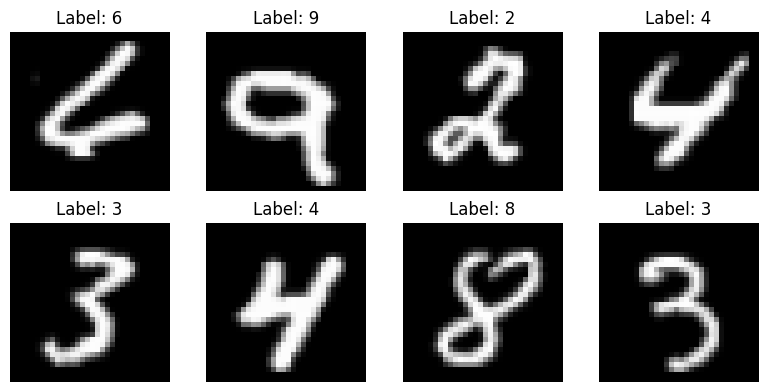

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(8, 4))

for index, ax in enumerate(axes.flat):
    display_image = images[index, 0] * 0.5 + 0.5
    ax.imshow(display_image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {labels[index].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()


**この塊の意味：バッチに入った画像8枚と正解を並べて表示します。**

`plt.subplots(2, 4)` は2行4列の描画場所を作ります。`for` は同じ処理の繰り返しです。`enumerate(axes.flat)` を使い、描画場所を順に取り出すと同時に、0からの番号 `index` も受け取ります。字下げされた処理を各場所で実行します。

`images[index, 0]` で1枚の1チャネルを選びます。`* 0.5 + 0.5` は前処理の正規化を戻す計算で、表示のために0〜1へ戻しています。学習データそのものを変更しているわけではありません。

`tight_layout()` は図同士の間隔を調整します。同じラベルでも筆跡が違うことを確認してください。モデルはこの違いを含む画像から規則性を学びます。


## 4. ResNetの構造を定義する

### 4.1 層と残差接続を自分で書く

このNotebookでは **ResNet-10Tのモデル定義を省略せずに書きます**。`torch.nn` の畳み込み・BatchNorm・プーリング・全結合層を組み合わせ、残差接続と順伝播も明示します。timmや別の自作Pythonファイルは読み込みません。

`BasicBlock` は2つの畳み込みを持つ残差ブロック、`ResNet10T` はモデル全体です。入力部のチャネル数は24→32→64、その後は64・128・256・512チャネルの4段階に残差ブロックを1つずつ置きます。

短縮版の `MNIST_CNN_short.py` だけは、同じ構成をtimmの `resnet10t` から作ります。明示版はtimm v1.0.24の標準構成に合わせていますが、実行による比較はまだ行っていません。

設定は白黒1チャネル・10クラス出力・事前学習なしです。学習1,000枚・10エポックで、精度より処理の理解を優先します。

参考：[構成の参照元](https://github.com/huggingface/pytorch-image-models/blob/v1.0.24/timm/models/resnet.py)、[ResNet原論文](https://arxiv.org/abs/1512.03385)。


### 4.2 各部品と画像の形

- **Conv2d**：畳み込みで局所的な特徴を取り出します。
- **BatchNorm2d**：学習時はミニバッチの統計を使い、評価時は学習中に蓄積した統計を使います。
- **ReLU**：負の値を0にする非線形な変換です。
- **残差接続**：畳み込みなどの結果に、入力側から渡した値を足します。形が違う場合は変換してそろえます。
- **プーリング**：空間方向の情報をまとめます。
- **Linear**：最後に10クラス分のスコアを作ります。

| 場所 | テンソルの形（Nは画像枚数） |
|---|---|
| 入力 | N × 1 × 32 × 32 |
| 入力部分の畳み込みとプーリング | N × 64 × 8 × 8 |
| layer1 | N × 64 × 8 × 8 |
| layer2 | N × 128 × 4 × 4 |
| layer3 | N × 256 × 2 × 2 |
| layer4 | N × 512 × 1 × 1 |
| 全体の平均プーリング・平坦化 | N × 512 |
| 全結合層 | N × 10 |

`model.forward_features(images)` で全結合層の前の特徴マップ、`model(images)` で最終スコアを得ます。最後の10個は数字0〜9の**スコア（logits）**で、まだ確率ではありません。


In [10]:
class BasicBlock(nn.Module):
    """2つの畳み込みと残差接続を持つブロック。"""

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3,
            stride=stride, padding=1, bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.act1 = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3, padding=1, bias=False,
        )
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.act2 = nn.ReLU(inplace=True)

        # 足し合わせる2つの経路の縦横・チャネル数をそろえる。
        if stride != 1 or in_channels != out_channels:
            pool = nn.AvgPool2d(
                kernel_size=2, stride=stride, ceil_mode=True, count_include_pad=False,
            ) if stride != 1 else nn.Identity()
            self.downsample = nn.Sequential(
                pool,
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.downsample = None

    def forward(self, x):
        shortcut = x
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.act1(x)
        x = self.conv2(x)
        x = self.bn2(x)
        if self.downsample is not None:
            shortcut = self.downsample(shortcut)
        x = x + shortcut
        x = self.act2(x)
        return x


class ResNet10T(nn.Module):
    """ResNet-10Tの構造をPyTorchの層で明示した教材用モデル。

    白黒入力・10クラス分類。短縮版のresnet10tと同じ層構成を使う。
    構成の参照: timm v1.0.24 の resnet10t / deep_tiered / avg_down。
    https://github.com/huggingface/pytorch-image-models/blob/v1.0.24/timm/models/resnet.py
    """

    def __init__(self, in_chans=1, num_classes=10):
        super().__init__()
        # 入力部: チャネル数を 1 → 24 → 32 → 64 と増やす。
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_chans, 24, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(24),
            nn.ReLU(inplace=True),
            nn.Conv2d(24, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1, bias=False),
        )
        self.bn1 = nn.BatchNorm2d(64)
        self.act1 = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # 4つの段階に残差ブロックを1つずつ配置する。
        self.layer1 = nn.Sequential(BasicBlock(64, 64, stride=1))
        self.layer2 = nn.Sequential(BasicBlock(64, 128, stride=2))
        self.layer3 = nn.Sequential(BasicBlock(128, 256, stride=2))
        self.layer4 = nn.Sequential(BasicBlock(256, 512, stride=2))
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

        # 畳み込みはKaiming初期化、BatchNormは重み1・バイアス0。
        # 全結合層にはnn.Linearの標準初期化を使う。
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(layer, nn.BatchNorm2d):
                nn.init.ones_(layer.weight)
                nn.init.zeros_(layer.bias)
        # 各残差ブロックの最後のBNだけ重みを0にして学習を始める。
        for layer in self.modules():
            if isinstance(layer, BasicBlock):
                nn.init.zeros_(layer.bn2.weight)

    def forward_features(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.act1(x)
        x = self.maxpool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return x

    def forward(self, x):
        x = self.forward_features(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x


**この塊の意味：残差ブロックとモデル全体の設計図を定義します。ここではまだモデルを作成したり、学習したりしていません。**

- `class ... (nn.Module)` は、PyTorchのモデルに必要な機能を引き継ぐクラスの定義です。`__init__` で層を準備し、`forward` でデータを通す順序を書きます。
- `nn.Conv2d` は畳み込みです。`kernel_size=3` は3×3のフィルタ、`padding=1` は周囲の埋め幅、`stride=2` は2画素ずつ移動する指定です。
- `nn.Sequential(...)` は、並べた層を順番に実行します。
- `BasicBlock.forward` の `x + shortcut` が残差接続です。両者の形が違う場合、`downsample` の平均プーリングと1×1畳み込みでそろえます。
- `self.layer1` から `self.layer4` は各段階の残差ブロックです。
- `AdaptiveAvgPool2d((1, 1))` と `torch.flatten(x, 1)` で各画像を512個の値にまとめ、`Linear(512, 10)` で10クラスのスコアにします。
- `self.modules()` で各層を取り出し、`nn.init` で重みの初期値を設定します。各ブロックの最後のBatchNormの重みを0にして、最初は残差側の寄与を0から始めます。

`model(images)` を呼ぶと `forward` が実行されます。層の定義・順伝播・初期化までをこのセルで追えます。


In [12]:
model = ResNet10T(in_chans=1, num_classes=10).to(device)

parameter_count = sum(parameter.numel() for parameter in model.parameters())

print(model)
print(f"学習するパラメータ数: {parameter_count:,}")

model.eval()
with torch.no_grad():
    example_images = images[:4].to(device)
    example_features = model.forward_features(example_images)
    example_logits = model(example_images)

print("入力:", example_images.shape)
print("畳み込み部分の出力:", example_features.shape)
print("モデル全体の出力:", example_logits.shape)


ResNet10T(
  (conv1): Sequential(
    (0): Conv2d(1, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(24, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  )
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act1): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act1): ReLU(inplace=True

**この塊の意味：作成したモデルについて、4枚の画像で入出力の形を確かめます。**

`ResNet10T(...)` はモデルの実体を作り、`.to(device)` はモデルをGPUまたはCPUに置きます。入力画像も同じ場所に置く必要があります。`images[:4]` で先頭4枚を選んでいます。

`model.parameters()` で重みやバイアスを取り出し、`numel()` で数値の個数を数え、`sum(...)` で合計します。`... for ... in ...` は繰り返しながら値を作る書き方です。ここでは各パラメータの要素数を順に合計しています。`{parameter_count:,}` は、表示する数値に桁区切りを付ける指定です。

`model.eval()` は評価モードにします。`with torch.no_grad():` の内側は、勾配を計算するための記録を作りません。`with` は、指定した設定をその塊の間だけ適用するときなどに使う構文です。今回は形を見るだけなので、重みの更新は不要です。

出力が `[4, 10]` なら、4枚それぞれに10クラス分のスコアが返っています。まだ学習前なので、この予測の正しさには意味を持たせません。


## 5. 損失関数と重みの更新

学習では、正解ラベルと予測から**損失（loss）**を計算し、損失を小さくするように重みを更新します。今回は多クラス分類で使う**交差エントロピー損失**と、更新方法の一つである**Adam**を使います。Adamは今回の学習設定であり、ResNet原論文の学習条件を再現するものではありません。

損失は、重みをどちらへ動かすかを決めるための数値です。今回の正解率は最大スコアのクラスが正しいかだけを数えるため、スコアが少し変わっても同じ値のままになることがあります。学習には勾配を計算できる交差エントロピーを使い、人が結果を読みやすい指標として正解率も記録します。**損失を計算するだけでは学習は起きません。** その後に勾配を計算し、更新処理を実行して初めて重みが変わります。


In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)


**この塊の意味：予測を採点する方法と、重みを更新する方法を用意します。**

`criterion` に損失関数、`optimizer` に更新処理を入れています。`model.parameters()` によって更新対象の重みを渡し、`lr` に学習率を指定します。このセルだけでは重みは更新されません。

**CrossEntropyLossには、Softmaxを付ける前のlogitsを渡します。** 正解は `[バッチ数]` の整数ラベルです。今回はラベルをone-hotベクトルへ変換する必要はありません。表示用の確率が欲しいときだけ、後でSoftmaxを使います。

損失と正解率は別の量です。正解率は「一番高いスコアのクラスが正しかった割合」で、損失はスコアの分布も反映します。同じ正解率でも損失は変わります。

検索語：`CrossEntropyLoss logits`、`softmax`、`Adam optimizer`、`learning rate`  
参考：[CrossEntropyLossの仕様](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)、[Adamの仕様](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)


## 6. 学習と検証

### 6.1 1エポック分の学習を関数にまとめる

1エポックは、今回選んだ学習用1,000枚を一巡することです。32枚ずつ取り出し、バッチごとに「予測 → 損失 → 勾配 → 更新」を繰り返します。

次のセルは関数の定義なので、実行しても学習はまだ始まりません。

学習データを繰り返し使うのは、初期状態から1回の更新ですべての対応を獲得できるとは限らないためです。ただし、長く学習するほど汎化性能がよくなるとは限りません。学習指標は「学習が進んでいるか」を調べる材料になり、採用時点は別の検証データで判断します。


In [14]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        predictions = logits.argmax(dim=1)
        total_loss += loss.item() * batch_size
        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

    return total_loss / total_samples, total_correct / total_samples


**この塊の意味：データを一巡し、重みを更新しながら平均損失と正解率を集計します。**

まず `model.train()` で学習モードにします。BatchNormがミニバッチの統計を使い、評価用の統計も更新します。`for images, labels in loader:` で画像とラベルのバッチを順に取り出し、両方を `device` に移します。

更新の中心は次の5行です。

| 処理 | 役割 |
|---|---|
| `optimizer.zero_grad()` | 前のバッチの勾配をリセットする |
| `logits = model(images)` | 順伝播で予測スコアを計算する |
| `loss = criterion(logits, labels)` | 正解とのずれを損失として計算する |
| `loss.backward()` | 誤差逆伝播で各重みに対する勾配を計算する |
| `optimizer.step()` | 勾配を使って重みを更新する |

`backward()` は勾配の計算、`step()` は更新で、別の処理です。PyTorchでは勾配が加算されるため、通常はバッチごとにリセットします。

後半は記録用です。`argmax(dim=1)` は10クラスの方向から最大スコアの位置を選びます。その位置0〜9が予測した数字です。`==` は一致の比較、`.sum()` は合計です。`+=` は現在の値への加算です。

バッチごとの平均損失に枚数を掛けて足し、最後に全枚数で割っています。最後の小さいバッチも含め、画像1枚あたりの平均にするためです。`return` で平均損失と正解率の2つを返します。

**理論との対応：** 順伝播・損失・逆伝播・最適化が、この更新部分に対応します。勾配の式を手で実装する代わりに、PyTorchの自動微分を使っています。

参考：[自動微分の説明](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html)、[学習ループの公式解説](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)

### 6.2 検証：学習の進み方と採用候補を評価する

学習の1エポックが終わるたびに、その時点のモデルで検証200枚を予測します。検証用の正解と比べて損失・正解率を計算しますが、この評価中にモデルを学習させません。学習データへの適合が進む一方で検証成績が悪化していないかを確認し、今回は検証損失を使って採用する時点を決めます。

次の `evaluate` は、**1つの固定したモデルを採点する関数**です。重みを選ぶ処理はこの関数の中ではなく、後の学習ループにある `if val_loss < best_val_loss:` が担当します。


In [15]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)
            predictions = logits.argmax(dim=1)
            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

    return total_loss / total_samples, total_correct / total_samples


**この塊の意味：モデルの重みと評価用の統計を固定し、渡されたデータで損失と正解率を測ります。**

学習と同じく画像をモデルへ入力し、予測と正解を比較します。違いは `backward()` と `optimizer.step()` を実行しないことです。**検証・テストでも正解ラベルは採点に使います。** ラベルを隠して計算するという意味ではなく、採点結果でその場の重みを更新しないという意味です。モデルの入力は画像だけで、正解ラベルは損失や正解率の計算へ渡します。

- `model.eval()`：評価モードへ切り替えます。このモデルのBatchNormは、学習中に蓄積した平均・分散を使い、検証・テストのバッチでそれらを更新しません。
- `torch.no_grad()`：勾配計算のための記録を止め、評価時のメモリ使用などを減らします。

`eval()` だけでは勾配の記録は止まりません。`no_grad()` だけではBatchNormは評価モードになりません。今回の評価では両方を指定し、optimizerによる更新も行いません。逆に `model.train()` を呼ぶだけで重みが自動的に学習されるわけでもありません。

各画像の損失を枚数で平均し、正解率は「正しく分類した枚数 ÷ 評価した総枚数」で求めます。最後の小さいバッチも含めて、各画像を同じ重みで集計しています。

**検証とテストで計算方法が同じでも、結果の用途は違います。** 検証の結果は候補モデルの選択に使い、テストの結果は選択後のモデルを評価するために使います。`evaluate` という関数名や `eval()` の指定だけで、データの役割や独立性が保証されるわけではありません。

参考：[PyTorch公式：評価モードと勾配モードの違い](https://docs.pytorch.org/docs/stable/notes/autograd.html#evaluation-mode-nn-module-eval)


### 6.3 学習・検証を繰り返し、採用する重みを選ぶ

ここから10エポック学習します。処理の順序は次のとおりです。

1. **学習**：学習1,000枚で損失・勾配を計算し、バッチごとに重みを更新する。
2. **検証**：そのエポック末のモデルを固定し、検証200枚の損失と正解率を測る。
3. **選択用の記録**：これまでより検証損失が小さければ、その時点のモデル状態をコピーして残す。
4. 1〜3を10エポック繰り返し、最後に記録した最良のモデル状態へ戻す。その後でテストする。

今回は、あらかじめ選択基準を**検証損失の最小値**と決めています。検証正解率は観察用にも表示しますが、重みの選択には使いません。損失と正解率は違う量なので、検証損失が最小のエポックと検証正解率が最大のエポックは一致しない場合があります。テストを見てから都合のよい選択基準へ変えることもしません。

最後のエポックを必ず採用しないのは、学習を続けた結果、学習データに合わせすぎることがあるためです。ただし、検証損失の最小値で選んでも、未知のデータやテストで最高の性能になる保証はありません。検証200枚から得られる判断にもばらつきがあるからです。

このセルを実行し直した場合は、モデル・optimizer・履歴を作り直して最初から学習します。前の学習に10エポックを追加する処理ではありません。


In [16]:
torch.manual_seed(SEED)
train_generator.manual_seed(SEED)
model = ResNet10T(in_chans=1, num_classes=10).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_state = None
best_epoch = 0
start_time = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = deepcopy(model.state_dict())
        best_epoch = epoch

    elapsed = time.perf_counter() - epoch_start
    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, acc {train_acc:.1%} | "
        f"val loss {val_loss:.4f}, acc {val_acc:.1%} | "
        f"{elapsed:.1f} sec"
    )

training_seconds = time.perf_counter() - start_time
model.load_state_dict(best_state)
model.eval()
print(f"学習・検証の合計時間: {training_seconds:.1f}秒")
print(f"採用した重み: epoch {best_epoch}（検証損失が最小）")


Epoch 1/10 | train loss 1.1981, acc 65.5% | val loss 2.5819, acc 15.0% | 0.2 sec
Epoch 2/10 | train loss 0.3104, acc 92.6% | val loss 0.3831, acc 87.5% | 0.1 sec
Epoch 3/10 | train loss 0.1194, acc 97.5% | val loss 0.2094, acc 92.5% | 0.2 sec
Epoch 4/10 | train loss 0.0440, acc 99.8% | val loss 0.2519, acc 91.5% | 0.2 sec
Epoch 5/10 | train loss 0.0251, acc 99.9% | val loss 0.2847, acc 90.0% | 0.2 sec
Epoch 6/10 | train loss 0.0209, acc 99.9% | val loss 0.2363, acc 93.0% | 0.1 sec
Epoch 7/10 | train loss 0.0240, acc 99.7% | val loss 0.3080, acc 90.0% | 0.2 sec
Epoch 8/10 | train loss 0.0890, acc 97.3% | val loss 0.4533, acc 85.0% | 0.2 sec
Epoch 9/10 | train loss 0.0610, acc 98.6% | val loss 0.2829, acc 89.0% | 0.1 sec
Epoch 10/10 | train loss 0.0241, acc 99.4% | val loss 0.2831, acc 91.5% | 0.1 sec
学習・検証の合計時間: 1.6秒
採用した重み: epoch 3（検証損失が最小）


**この塊の意味：学習と検証を交互に実行し、記録を残して採用する重みを選びます。**

`history` は名前と値を対応づける**辞書（dict）**です。`history["train_loss"]` で記録先のリストを選び、`append(...)` で結果を追加します。`range(1, EPOCHS + 1)` は1からEPOCHSまでの整数を順に作ります。終点は含まないため `+ 1` が必要です。

`float("inf")` は無限大で、最初の検証損失を必ず採用するための初期値です。`None` はまだ値がないことを表します。`state_dict()` は重み・バイアスに加え、BatchNormの蓄積した平均・分散なども辞書として取り出します。採用時点の予測を再現するため、これらも一緒に戻す必要があります。`deepcopy` で独立したコピーにし、後の学習で「最良時点の重み」まで変わらないようにします。

`load_state_dict(best_state)` で、最終エポックではなく選んだエポックの重みに戻します。`:.4f` は小数点以下4桁、`:.1%` は小数点以下1桁の百分率で表示する指定です。`time.perf_counter()` の差で処理時間を測ります。表示時間には検証も含みます。

**出力の見方：** 最初の数エポックで損失が下がり、正解率が上がるかを見ます。短い学習では値が多少揺れます。特定の正解率になることは保証されません。

**今後につながる知識：** 検証で最良の重みを選ぶことと、改善が止まったら学習を終える**Early Stopping**は別です。今回は10エポックすべて実行します。  
検索語：`checkpoint`、`early stopping`、`hyperparameter tuning`


## 7. 学習曲線

数値だけでは変化を追いにくいため、学習中の損失と正解率をグラフにします。横軸はエポック、縦軸はそれぞれの指標です。


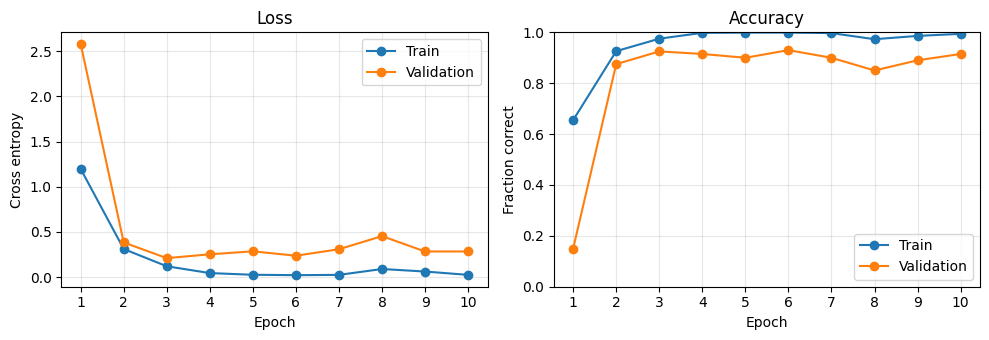

In [17]:
epoch_numbers = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(epoch_numbers, history["train_loss"], marker="o", label="Train")
axes[0].plot(epoch_numbers, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross entropy")

axes[1].plot(epoch_numbers, history["train_acc"], marker="o", label="Train")
axes[1].plot(epoch_numbers, history["val_acc"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Fraction correct")
axes[1].set_ylim(0, 1)

for ax in axes:
    ax.set_xticks(list(epoch_numbers))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**この塊の意味：辞書にためた記録を、2つの折れ線グラフにします。**

`plot(x, y)` は横軸と縦軸の値を結んで表示します。`label` は線の名前、`legend()` はその凡例です。`list(...)` は値の並びをリストに変換します。

**見る場所：**

- 学習・検証の損失が下がる：重みの更新に使っていない検証データでも予測が改善していることを示します。ただし、検証はモデル選択に使うため、最終的な性能はテストで評価します。
- 学習損失だけ下がり、検証損失が上がり続ける：**過学習**の兆候です。
- 両方とも改善しない：学習率、データ、モデルや実装を確認する手がかりです。原因はグラフだけでは断定できません。

短い学習なので、必ず過学習の形が出るわけではありません。また、今回の学習指標は「重みが更新される途中・BatchNormはバッチの統計を使用」、検証指標は「そのエポック末の重み・BatchNormは蓄積した統計を使用」で測っています。この違いによって、検証正解率の方が高い場合もあります。

検索語：`learning curve`、`overfitting`、`underfitting`


## 8. テストと誤分類の確認

### 8.1 選択を終えたモデルをテストする

学習と検証による重みの選択が終わったので、ここで初めてテスト200枚の性能を測ります。第6節の最後で、モデルは既に検証損失が最小だったエポックの状態へ戻っています。テスト時にはその重みと前処理を固定します。

**テストの目的は、モデル作りに使っていないデータで、選び終えたモデルの予測性能を見積もることです。** 学習成績には重みを合わせた影響があり、検証成績には候補を選んだ影響があります。その両方から分けて残したテストデータを、最終評価に使います。

この値を将来の性能の目安にするには、テストデータが想定する利用条件を代表し、学習・モデル選択への情報の混入がないことが重要です。今回の結果は公式MNISTテストの先頭200枚に対する結果です。全10,000枚を評価した結果でも、スマートフォンで撮った数字など、別の条件での性能保証でもありません。


In [18]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"採用エポック: {best_epoch}")
print(f"テスト損失: {test_loss:.4f}")
print(f"テスト正解率: {test_acc:.2%}")


採用エポック: 3
テスト損失: 0.2074
テスト正解率: 95.00%


**この塊の意味：検証で選んだモデルについて、選択に使っていないテストデータで損失と正解率を表示します。**

`evaluate` は検証時と同じ関数です。`test_loader` を渡すことでテストを採点します。正解率は正しく分類した枚数の割合、損失は予測スコアと正解の対応を評価する別の指標です。

例えば正解率95%なら、この200枚のうち190枚を正しく分類したという意味です。テスト200枚では1枚の正誤で正解率が**0.5パーセントポイント**変わります。少数の評価データから得た値には標本によるばらつきがあり、95%と表示されても、将来の画像で常に95%正しいと断定できません。乱数のseedを固定することも、その不確かさをなくすことではありません。

**テスト結果を改善のための選択に使うと、そのテストは最終評価用としての役割を失います。** 例えばテスト成績を見て学習率や採用エポックを変え、最も良い結果を報告すると、成績を実際よりよく見積もるおそれがあります。通常、改善の判断には検証を使います。テストを見た後に変更したモデルを独立に評価したい場合は、その変更に使っていない評価データを確保するなど、評価計画を見直します。

同じ固定モデルでテストセルを再実行したり、この後に混同行列・誤分類画像を表示したりすること自体が問題なのではありません。**その結果を見て何を選び、何を変更したか**が重要です。この教材では、図を現在のモデルの結果を理解するために使います。


### 8.2 混同行列で、どの数字を間違えたかを見る

正解率は全体を1つの数にまとめた指標です。**混同行列（confusion matrix）**では、正解の数字と予測の数字の組み合わせを数えます。まず、各画像の予測をCPU側に集めます。


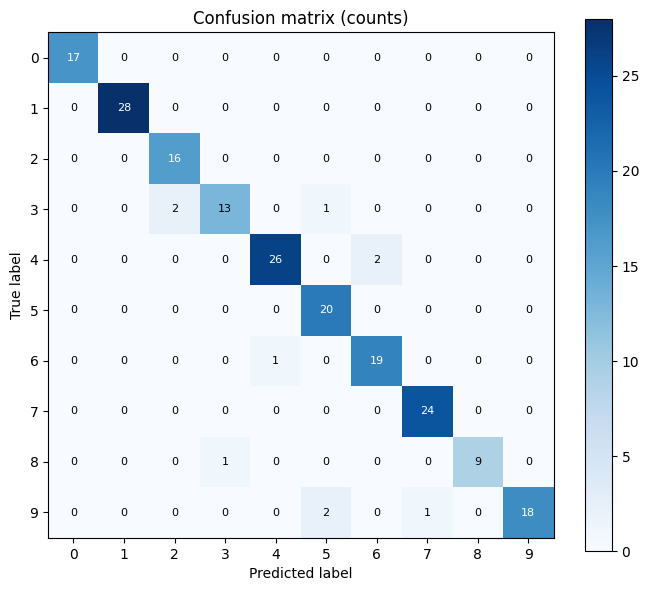

In [19]:
all_predictions = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu())
        all_labels.append(labels)

all_predictions = torch.cat(all_predictions)
all_labels = torch.cat(all_labels)

confusion = torch.zeros(10, 10, dtype=torch.int64)
for true_label, predicted_label in zip(all_labels.tolist(), all_predictions.tolist()):
    confusion[true_label, predicted_label] += 1

fig, ax = plt.subplots(figsize=(7, 6))
heatmap = ax.imshow(confusion.numpy(), cmap="Blues")
for row in range(10):
    for col in range(10):
        color = "white" if confusion[row, col] > confusion.max() / 2 else "black"
        ax.text(col, row, str(confusion[row, col].item()),
                ha="center", va="center", color=color, fontsize=8)

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion matrix (counts)")
fig.colorbar(heatmap, ax=ax)
plt.tight_layout()
plt.show()


**この塊の意味：全画像の予測をつなぎ、正解×予測の10×10表に集計します。**

`.cpu()` はGPU上の値をCPUへ移します。`torch.cat(...)` はバッチごとのテンソルをつなぎます。`.tolist()` はPythonのリストへ、`.numpy()` はグラフ表示などに使うNumPy配列へ変換します。

`torch.zeros(10, 10, ...)` で、最初は全部0の集計表を作ります。`dtype=torch.int64` は整数の型です。`zip(...)` は2つの並びから対応する要素を一緒に取り出します。正解を行、予測を列として1ずつ加算しています。後半は数字と色を図に配置するための処理です。`str(...)` は値を文字列に変換します。

**出力の見方：** 対角線上は正しく分類した枚数です。例えば行4・列9は「正解は4だが9と予測した枚数」です。この図は割合ではなく件数なので、クラスごとの枚数も影響します。

**今後につながる知識：** クラス数が偏るデータでは、全体の正解率だけで判断しないことが大切です。クラス別の再現率や適合率、F1なども使います。  
検索語：`confusion matrix`、`precision recall F1`、`class imbalance`


誤分類した枚数: 10


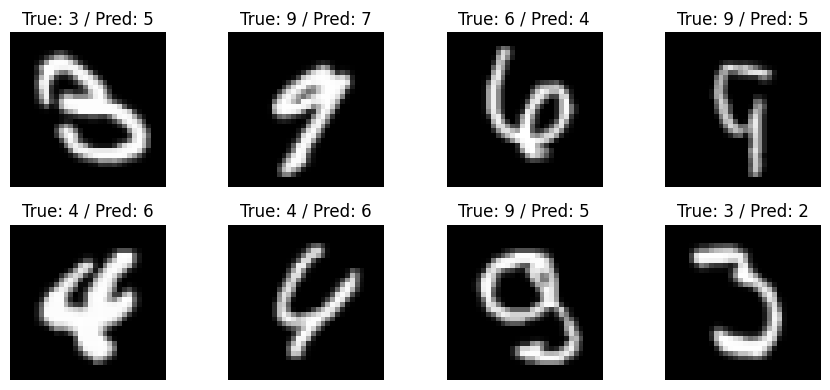

In [20]:
wrong_indices = torch.where(all_predictions != all_labels)[0]
print("誤分類した枚数:", len(wrong_indices))

if len(wrong_indices) == 0:
    print("今回のテストでは誤分類がありませんでした。")
else:
    fig, axes = plt.subplots(2, 4, figsize=(9, 4))
    for index, ax in enumerate(axes.flat):
        ax.axis("off")
        if index < len(wrong_indices):
            dataset_index = wrong_indices[index].item()
            image, label = test_dataset[dataset_index]
            predicted = all_predictions[dataset_index].item()
            ax.imshow(image[0] * 0.5 + 0.5, cmap="gray", vmin=0, vmax=1)
            ax.set_title(f"True: {label} / Pred: {predicted}")
    plt.tight_layout()
    plt.show()


**この塊の意味：間違えた画像のうち、データ順で最初の最大8枚を表示します。**

`!=` は不一致の比較、`torch.where(条件)[0]` は条件を満たす位置を取り出します。テストLoaderは順序を変えていないので、この位置で元の画像を取り出せます。`if ... else ...` で誤分類が0枚の場合にも対応しています。

**出力の見方：** `True` は正解、`Pred` は予測です。線の欠けや傾き、別の数字に似た書き方など、画像そのものを確認します。ここに出る8枚だけで誤り全体を代表しているとは限りません。

研究では、指標の数値と元画像を両方見ます。誤りにはモデルの能力、データの偏り、ラベルの問題など複数の原因があり得ます。

ここで見つけた誤りを理由に前処理やモデルを変更した場合、その変更はテストの情報を使っています。変更後に同じテストで成績が上がっても、未使用データでの改善を確かめたことにはなりません。開発中の誤り分析は主に検証データで行い、最終テストでの分析は、報告するモデルを固定した上で結果の特徴と限界を説明するために使います。


## 9. 学習済みモデルの保存と再利用

### 9.1 重みと実験条件を保存する

カーネルを再起動すると、メモリ上のモデルは消えます。学習済みの重みをファイルに保存しておけば、再学習せずに推論できます。

この教材では、重みを `resnet10t_mnist.pt`、設定と結果を `resnet10t_run_summary.json` に保存します。同じセルを再実行すると、この2つのファイルは今回の結果で上書きします。


In [21]:
model_path = OUTPUT_DIR / "resnet10t_mnist.pt"
summary_path = OUTPUT_DIR / "resnet10t_run_summary.json"

torch.save(model.state_dict(), model_path)

summary = {
    "model": "ResNet10T", "implementation": "explicit_pytorch",
    "pretrained": False,
    "input_size": [1, 32, 32],
    "seed": SEED,
    "train_size": TRAIN_SIZE,
    "val_size": VAL_SIZE,
    "test_size": len(test_dataset),
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "normalization": {"mean": [0.5], "std": [0.5]},
    "best_epoch": best_epoch,
    "test_loss": test_loss,
    "test_accuracy": test_acc,
    "training_seconds": training_seconds,
    "parameter_count": parameter_count,
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "device": str(device),
    "history": history,
    "train_indices": train_dataset.indices,
    "val_indices": val_dataset.indices,
    "test_indices": list(test_dataset.indices),
}
with summary_path.open("w", encoding="utf-8") as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

print("重み:", model_path)
print("条件と結果:", summary_path)


重み: /home/B3CNNpart/outputs/resnet10t_mnist.pt
条件と結果: /home/B3CNNpart/outputs/resnet10t_run_summary.json


**この塊の意味：モデルの重みと、今回の実験を説明する情報を別々に保存します。**

`torch.save(...)` で重みの辞書を保存します。このファイルだけに、モデルを定義するPythonコードや前処理がすべて入るわけではありません。再利用には同じ構造と前処理が必要です。

`with ...open("w", encoding="utf-8") as file:` は、文字ファイルを書き込み用に開き、塊を抜けると閉じます。`json.dump(...)` は辞書を読みやすいJSON形式で書きます。分割に使った画像番号も記録しているので、seedだけに頼らずどの画像を使ったか確認できます。

**今後につながる知識：** 推論用の重みに加え、学習を途中から再開したい場合はoptimizerの状態やエポックなども保存します。今回は推論用の保存です。

1枚をバッチにした形: torch.Size([1, 1, 32, 32])
正解: 7
予測: 7


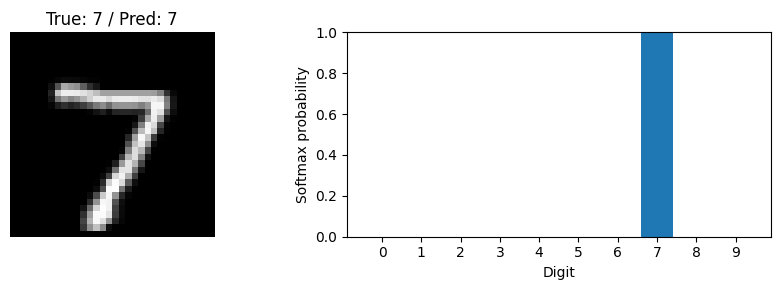

In [22]:
loaded_model = ResNet10T(in_chans=1, num_classes=10).to(device)
saved_weights = torch.load(model_path, map_location=device, weights_only=True)
loaded_model.load_state_dict(saved_weights)
loaded_model.eval()

image, true_label = test_dataset[0]
input_batch = image.unsqueeze(0).to(device)

with torch.no_grad():
    logits = loaded_model(input_batch)
    probabilities = torch.softmax(logits, dim=1)
    predicted_label = probabilities.argmax(dim=1).item()

print("1枚をバッチにした形:", input_batch.shape)
print("正解:", true_label)
print("予測:", predicted_label)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].imshow(image[0] * 0.5 + 0.5, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"True: {true_label} / Pred: {predicted_label}")
axes[0].axis("off")

axes[1].bar(range(10), probabilities[0].cpu().numpy())
axes[1].set_xticks(range(10))
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Digit")
axes[1].set_ylabel("Softmax probability")
plt.tight_layout()
plt.show()


**この塊の意味：新しく作ったモデルへ保存済みの重みを読み込み、1枚の画像を分類します。**

- `torch.load(..., map_location=device, weights_only=True)` で重みを読み、`load_state_dict(...)` でモデルに設定します。`map_location` で読み込み先の計算場所を指定します。自分で保存したファイルを使います。
- `image.unsqueeze(0)` は先頭にバッチの次元を追加します。`[1, 32, 32]` が `[1, 1, 32, 32]` になり、1枚でも学習時と同じ次元数で入力できます。
- `softmax(logits, dim=1)` はクラス方向のスコアを合計1の値に変換します。今回は図に出すために使います。学習時のCrossEntropyLossの前には付けません。

**出力の見方：** 棒が最も高い数字が予測です。Softmaxの値が0.99でも、未知の条件で「必ず99%正しい」と保証するものではありません。モデルは誤った予測に大きな値を付けることもあります。

保存後、別のNotebookで使う際は、このNotebookと同じBasicBlock・ResNet10Tの定義（1チャネル入力・10クラス）と同じ前処理を用意し、重みを読み込みます。再び学習ループを実行する必要はありません。

**今後につながる知識：** 紙に書いた数字を撮影すると、MNISTと背景色、余白、傾き、線の太さなどが変わります。サイズを32×32にするだけでは同じ入力条件になりません。このような分布の違いを考える入口が**ドメインシフト**です。

検索語：`model calibration`、`domain shift`、`inference preprocessing`

このセルは、既に評価に使ったテスト画像1枚で保存・読み込み・推論の流れを確認する例です。新しい独立したテストではなく、1枚の正誤からモデル全体の性能を判断するものでもありません。実際の推論では、正解ラベルが分からなくても画像だけから予測できます。


## 10. 次に調べるための案内

ここまでで、データの読み込み、前処理、分割、モデル定義、学習、検証による重みの選択、テスト、保存と推論を実行しました。次週の内容で知らない語が出たら、以下を入口にしてください。追加の課題はありません。

| 調べたいこと | 検索語 | 入口・資料の使い方 |
|---|---|---|
| Pythonの文法 | list / dict / function / class | [Python公式（日本語）](https://docs.python.org/ja/3/tutorial/)：構文の意味を確認 |
| 一連の実装を見直す | PyTorch Learn the Basics | [公式の入門](https://docs.pytorch.org/tutorials/beginner/basics/intro.html)：各処理を章ごとに確認 |
| 自分の画像を読み込む | custom Dataset / ImageFolder | [Datasetの説明](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)、[ImageFolder](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html)：フォルダやラベルの形式を確認 |
| 層の引数と出力サイズ | Conv2d / Linear / MaxPool2d | [torch.nn](https://docs.pytorch.org/docs/stable/nn.html)：引数・既定値・Shape欄を見る |
| CNNの発展を知る | AlexNet / ResNet / ConvNeXt | [AlexNet（2012）](https://proceedings.neurips.cc/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf)、[ResNet（2015年公開）](https://arxiv.org/abs/1512.03385)、[ConvNeXt（2022）](https://arxiv.org/abs/2201.03545)：提案の目的と構造を読む |
| 学習済みモデルを使う | pretrained weights / transfer learning / fine-tuning | [転移学習の公式入門](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)：重みの再利用を学ぶ |
| 評価指標を選ぶ | accuracy / precision / recall / F1 | [scikit-learnの評価指標](https://scikit-learn.org/stable/modules/model_evaluation.html)：指標の定義を確認 |
| 実験を再現する | seed / reproducibility / checkpoint | [PyTorchの再現性](https://docs.pytorch.org/docs/stable/notes/randomness.html)：保証の範囲と設定を確認 |

### 調べるときのコツ

- **機能名＋ライブラリ名**で探します。例：`PyTorch CrossEntropyLoss logits`。
- 公式ドキュメントでは、引数（Parameters）、入出力の形（Shape）、使用例（Examples）を確認します。
- インターネット上のコードは、使用ライブラリのバージョンが自分と同じとは限りません。このNotebook冒頭のバージョン表示を使って確認します。
- 論文の「最高性能」は、発表年・データセット・評価指標・実験条件とセットで読みます。古いモデルでも学ぶ価値はありますが、教材での採用と現在の性能順位は別の話です。

### エラーが出たとき

| 表示・症状 | 最初に確認すること |
|---|---|
| `NameError` | 変数を作るセルを先に実行したか。必要なら再起動して先頭から実行 |
| `ModuleNotFoundError` | 必要なライブラリを入れた環境と、選んだカーネルが同じか |
| `IndentationError` / `SyntaxError` | インデント、括弧、引用符、全角記号の混入 |
| shape / size mismatch | `.shape` で入力と層の大きさを確認 |
| tensors on different devices | モデル・画像・ラベルを同じ `device` に置いたか |
| GPUがあるのにCPUになる | READMEのGPU環境の確認事項を参照 |
| ダウンロードに失敗する | インターネット接続やプロキシを確認し、再実行 |
| メモリ不足 | 不要な処理を閉じる、カーネルを再起動、バッチ数を小さくする |

エラーは最後の行に種類と理由、その上に問題の場所が表示されます。質問するときは、セルのコード・エラーメッセージ・バージョン表示を一緒に残すと状況を伝えやすくなります。
